# Paper figures (v2, new fiducial)

Copy of `2026-11-20_paper_figures.ipynb` (left as is) for the **new fiducial**, decided 2026-11-22 in `2026-11-19_v2_checks.ipynb` §6.
- **Training set:** `_p5_n10000` × `_biasnoisenestv2_p9_n320000` × `_noisefly`, noise in θ, $n_\mathrm{train}=10\,000$ cosmologies, $b_x=32$.
- **Test sets:** independent IC phases for coverage (`_coveragev2_p5_n1000`) and the SHAMe-cosmology CV set (`_cvshamev2_p0_n1000`).
- **Statistics:** P_gm uses the "1" operator.

**Fiducial:** $k_\mathrm{max}^{P_\mathrm{gg}}=0.37$, $k_\mathrm{max}^{P_\mathrm{gm}}=0.37$ (was 0.24), $k_\mathrm{max}^{B}=0.24$ (provisional, being chosen from the §7 kb slice in 11-19). Set in `generate_config_inference.FIDUCIAL_MASKS`.

**Hyperparameters:** from the `-rand16` sweeps at the fiducial cuts.
- Combos with P_gm use the kpgm0.37 sweeps. Their models are named `_best-rand16-topkpgm0.37[_nbest{n}][_seed{s}]`.
- P and P+B are unchanged (`_best-rand16...`).
- The old kpgm0.24-sweep models (plain `_best-rand16` for P_gm combos) are kept for the hyperparameter-transfer appendix.

**Ensemble:** an equal-weight $K=3$ mixture of the top-3 hyperparameter settings.
- **Contours, coverage, posteriors** (Figs 3–7, appendices): `top3_settings`. These are best_runs.txt lines 0–2, seed 0, which at the fiducial cut are the sweep trials themselves.
- **FoB / FoM vs $k_\mathrm{max}$ and vs $N_\mathrm{train}$** (Figs 8–11): **`top3_fresh`**. This is the same three settings, but wherever a member would be a sweep trial (seed 0 at the sweep cut, $b_x=32$, $n_\mathrm{train}=10^4$), its **seed-1 retrain** is used instead. The sweep trials were selected on val loss, so their posterior widths are biased (winner's curse: FoM off by up to ±50% at the fiducial cut; 11-19 §6c, §7). With fresh networks, every point on a curve is an equally unselected training.

**Status of the first versions (2026-11-24).** `eku.set_allow_partial_ensembles(True)` (cell 2): where fewer than 3 members have a test output, the top 1 (or top 1+2) is used, and each figure cell prints which points did (`report_partial_ensembles`). Partial builds are never cached. Set it to False for the final figures.

| Fig | Ensemble used now | What will change |
|---|---|---|
| 3, B1 (CV mean) | P, P+B: K=3. P+P$_\mathrm{gm}$+B: **top network only** | P+P$_\mathrm{gm}$+B, when CV-mean tests of settings 2-3 run (not submitted) |
| 4, 5 (coverage) | **top network only**, all combos (all 1000 rows) | all, when coverage of settings 2-3 runs (not submitted) |
| 6, 7, B2 (SHAMe, matched) | K=3 | P+P$_\mathrm{gm}$+B, if setting 3 changes (bydsd9rq is weak; the setting-3 search is running) |
| 8 (FoB vs $k_\mathrm{max}^B$, $k_\mathrm{max}^{P_\mathrm{gm}}$) | K=3 for P+B and P+P$_\mathrm{gm}$+B | P+P$_\mathrm{gm}$+B setting 3 along both slices if it changes; P+P$_\mathrm{gm}$ curves (slices not run) |
| 9 (overall $k_\mathrm{max}$) | **top network only** (K=1 at every point, for a consistent curve) | whole figure, once settings 2-3 are trained at the 8 other cuts (not submitted) |
| 10, 11 (convergence) | **top network only**; most grid points still filling their inner500 rows | whole figure: grid running; settings 2-3 grids not submitted |
| A | missing (1000 CV realizations deferred) | - |
| C (sweep ranking) | complete for the fiducial and kb0.11 sweeps | adds setting 1 seed 2 at the fiducial cut when trained (not submitted); setting 3 if the search replaces it |

P+P$_\mathrm{gm}$ (sweep done 2026-11-24): its fiducial networks are running (setting 1 seeds 0/1; settings 2-3 seed 0 copies and seed-1 retrains), so it appears with the top network first, then K=3.

**Saved figures are first versions too.** They are written as usual; the per-figure report (the authoritative list of what is partial) is saved next to them as `FIGURE_STATUS.md` in `figures/2026-11-22_paper_figures/` and `figures/paper_figures_latest/`.

Missing points are reported, not faked.

Plotting logic is in `code/plotter_figs.py`, and tags / masks / ensemble members are in `code/ensemble_kmax_utils.py`. Results use **un-reparameterized** parameters ($\Omega_\mathrm{m}$, $\sigma_8$, $b_1$) unless noted.

In [ ]:
import os
import sys
from pathlib import Path

# v2 trees (code_auxiliary/env_v2.sh); must be set before importing paths / data_loader
os.environ["MUCHISIMOCKS_DATA"] = "/scratch/kstoreyf/muchisimocks/data_v2"
os.environ["MUCHISIMOCKS_RESULTS"] = "/scratch/kstoreyf/muchisimocks/results_v2"

REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT / "code"))

import ensemble_kmax_utils as eku
import plotter_figs as pf

%load_ext autoreload
%autoreload 2

print("data:", pf.paths.DIR_DATA, "| results:", pf.paths.DIR_RESULTS)
print("train:", pf.TAG_PARAMS_TRAIN, pf.TAG_BIASPARAMS_TRAIN, pf.TAG_NOISE_TRAIN)
print("fiducial:", eku.FIDUCIAL_CONFIGS)

pf.configure_figures(
    save=True,
    fig_dir=REPO_ROOT / "figures" / "2026-11-22_paper_figures",
    fig_dir_latest=REPO_ROOT / "figures" / "paper_figures_latest",
    ext="pdf",
)

In [ ]:
# Fiducial ensemble for the contour / coverage / posterior figures: top-3 settings, seed 0 (sweep trials at the
# fiducial cut). Figs 8-11 switch to "top3_fresh" in their own cells (see the header). Options: eku.ENSEMBLE_SCHEMES
for scheme in ("top3_settings", "top3_fresh"):
    eku.set_ensemble_scheme(scheme)
    print(scheme)
    for stats, mask in eku.FIDUCIAL_CONFIGS:
        print(f"  {'_'.join(stats):15s}", [eku.model_dir(stats, mask, n).name.split("ntrain10000")[-1] for n in range(eku.N_ENSEMBLE_K)])
eku.set_ensemble_scheme("top3_settings")

# First versions of the figures (2026-11-24): where fewer than K=3 members have a test output, use the top 1
# (or top 1+2) and report it under each figure. Those points/curves will change when the missing members finish.
# Partial builds are never cached. Set False for the final figures (then incomplete points are just skipped).
eku.set_allow_partial_ensembles(True)
# Each figure cell's partial-ensemble report is also written next to the saved figures, so the saved PDFs carry
# their status: FIGURE_STATUS.md in fig_dir and fig_dir_latest (rewritten on every full run of this notebook).
import datetime
eku.start_status_files(
    [pf.FIG_DIR / "FIGURE_STATUS.md", pf.FIG_DIR_LATEST / "FIGURE_STATUS.md"],
    f"# Figure status ({datetime.datetime.now():%Y-%m-%d %H:%M}, notebooks/2026-11-22_paper_figures.ipynb)\n\n"
    "FIRST VERSIONS: where a figure lists PARTIAL points (K<3) or says 'top network only', that figure is not the "
    "final K=3 ensemble and will change.\n",
)


## 1. mMocks overview

Pipeline schematic - see paper


## 2. Statistics: training-set ranges

Median with 16–84% and 1–99% bands over the fiducial noisy training set.

- **SHAMe lines are unchanged from v1:** SHAMe P, P_gm and B were computed from the SHAMe catalogs and N-body matter field (`data/data_shame/data_nbar*/`, March 2026), and their binning matches v2 training (32 P/P_gm bins, 203 triangles). The v2 P_gm fix changed the *muchisimocks* side to agree with SHAMe's matter field, so the P_gm training band is the part that moved.
- **All three statistics are complete** for the v2 training set (P, P_gm, B: 320,000 rows each; bispec job 7975566 finished 2026-11-17), so the bispectrum band now uses every cosmology.


In [ ]:
pf.plot_fig2_statistics_ranges()


## 3. Cosmic variance test (fixed cosmology, mean)

Contour plot on the mean of 1000 fixed-cosmo mocks. All four fiducial statistic combinations ($K{=}3$ ensemble).


In [ ]:
pf.plot_fig3_cosmic_variance_contours()
eku.report_partial_ensembles("Fig 3")


## 4. Coverage test — prediction bias

Median and 16–84% of $\theta^{\mathrm{pred}} - \theta^{\mathrm{true}}$ vs true parameter value.


In [ ]:
pf.plot_fig4_coverage_binned_diff()
eku.report_partial_ensembles("Fig 4")


add avg of the sigmas on top - if well calibrated, should match


## 5. Coverage test — PP plots

Nominal credibility vs empirical coverage of the central equal-tailed credible interval.

Same top-model coverage samples as Fig. 4 (new $k_{p,\mathrm{max}}=0.37$ masks).


In [ ]:
pf.plot_fig5_coverage_pp_center()
eku.report_partial_ensembles("Fig 5")


## 6. SHAMe test

OOD galaxy catalog ($\bar n = 0.00022\,h^3/\mathrm{Mpc}^3$). Contours for all fiducial statistics ($K{=}3$ ensemble).


In [ ]:
pf.plot_fig6_shame_contours()
eku.report_partial_ensembles("Fig 6")


## 7. Number density: SHAMe vs phase-matched mocks

Ensemble posteriors (P + P$_{\rm gm}$ + B) for the SHAMe high-fidelity mock at 3 number densities (filled), and the phase-matched mock (SHAMe ICs + our forward model, mean of 10 noise realizations) at the same densities (unfilled, orange shades matched by $\bar{n}$). Matched and SHAMe share the truth at each $\bar{n}$; the offset between a filled and unfilled contour of the same shade is the model-mismatch part of the SHAMe bias. (Replaces the noisy/noiseless CV-mean overlays.)

In [ ]:
# Omega_m, sigma8, b1 plus b2 and bs2 (user, 2026-11-24)
pf.plot_fig7_noise_impact_contours_nbars(param_names=list(pf.PARAM_NAMES_ZOOM) + ["b2", "bs2"])
eku.report_partial_ensembles("Fig 7")


## 8. Scale dependence of constraints

**Fig. 8 (FoB):** SHAMe OOD FoB$(\Omega_m,\,\sigma_8,\,b_1)$ at fixed $k_\mathrm{max}^{P_{gg}}=0.37$, $K{=}3$ **fresh** ensemble (`top3_fresh`). Top: P_gm $k_\mathrm{max}$ fixed at the fiducial $0.37$, bispec on $x$; bottom: bispec fixed at $0.24$, P_gm on $x$.

The P_gm-on-$x$ panel needs the new-hyperparameter kpgm slices (not run yet), so it is mostly empty for now.


In [ ]:
# FoB / FoM figure: fresh networks at the sweep cut (see header)
eku.set_ensemble_scheme("top3_fresh")
pf.plot_fig8_scale_dependence_fob3_nbars()
eku.report_partial_ensembles("Fig 8")
eku.set_ensemble_scheme("top3_settings")


## 9. Overall $k_\mathrm{max}$ — FoM($\Omega_\mathrm{m}$, $\sigma_8$, $b_1$)

SHAMe OOD **marginal** FoM for each of the three key parameters vs a shared overall scale cut ($K{=}3$ **fresh** ensemble, `top3_fresh`), three panels. For $k_\mathrm{max}\le 0.24$ every statistic uses that cut; for $k_\mathrm{max}>0.24$, $P_{gg}$ continues while $B$ and $P_{gm}$ stay at $0.24$.

**Open (2026-11-22):** B and P$_{\rm gm}$ still share one cap at $0.24$ (`eku.KCUT_FID_OVERALL_CAP`). Since the fiducial P$_{\rm gm}$ is now $0.37$, the alternative is to cap each statistic at its own fiducial; that needs new P$_{\rm gm}$-combo models above 0.24.


In [ ]:
# FoB / FoM figure: fresh networks at the sweep cut (see header)
eku.set_ensemble_scheme("top3_fresh")
# First version: top network only at every point (k_members=1). The fiducial point already has all 3
# members while the other points have 1, so mixing would make the curve inconsistent. Drop k_members once
# settings 2-3 exist everywhere.
pf.plot_fig9_scale_dependence_overall_kmax_fom3_nbars(k_members=1)
eku.report_partial_ensembles("Fig 9", note="FIRST VERSION: top network only (K=1) at every point; the whole figure changes with K=3")
eku.set_ensemble_scheme("top3_settings")


## 10. Convergence: $P_{gg}+P_{gm}+B_{ggg}$ (3D FoM / FoB)

Coverage-test 3D FoM / FoB vs $N_\mathrm{train}$.

Uses the **fresh** ensemble (`top3_fresh`). At $N_\mathrm{train}=10^4$ that needs coverage tests of the seed-1 fiducial members, which are not run yet.


In [ ]:
# FoB / FoM figure: fresh networks at the sweep cut (see header)
eku.set_ensemble_scheme("top3_fresh")
# First version: top network only at every point (k_members=1). The fiducial point already has all 3
# members while the other points have 1, so mixing would make the curve inconsistent. Drop k_members once
# settings 2-3 exist everywhere.
pf.plot_fig10_convergence_pgg_b_pgm(k_members=1)
eku.report_partial_ensembles("Fig 10", note="FIRST VERSION: top network only (K=1) at every point; the whole figure changes with K=3")
eku.set_ensemble_scheme("top3_settings")


## 11. Convergence: all stat combos (marginal FoM / FoB)

Coverage-test marginal FoM / FoB vs $N_\mathrm{train}$ for each fiducial statistics combination.

Uses the **fresh** ensemble (`top3_fresh`). At $N_\mathrm{train}=10^4$ that needs coverage tests of the seed-1 fiducial members, which are not run yet.


In [ ]:
# FoB / FoM figure: fresh networks at the sweep cut (see header)
eku.set_ensemble_scheme("top3_fresh")
# First version: top network only at every point (k_members=1). The fiducial point already has all 3
# members while the other points have 1, so mixing would make the curve inconsistent. Drop k_members once
# settings 2-3 exist everywhere.
pf.plot_fig11_convergence_all_combos(k_members=1)
eku.report_partial_ensembles("Fig 11", note="FIRST VERSION: top network only (K=1) at every point; the whole figure changes with K=3")
eku.set_ensemble_scheme("top3_settings")


---
## Appendix A. Mean-of-stats vs per-realization


In [ ]:
try:  # needs the 1000 CV realizations (deferred): skip without stopping a full run
    pf.plot_figA_mean_vs_indiv_means_contours()
    eku.report_partial_ensembles("Fig A")
except FileNotFoundError as e:
    print("Fig A: not made yet:", str(e)[:300])
    eku.report_partial_ensembles("Fig A", note="NOT MADE (inputs missing)")


## Appendix B. Full posteriors (cosmic variance & SHAMe)


In [ ]:
pf.plot_figB1_cosmic_variance_full_posteriors()
eku.report_partial_ensembles("Fig B1")


In [ ]:
pf.plot_figB2_shame_full_posteriors()
eku.report_partial_ensembles("Fig B2")


## Appendix C. Network scatter and hyperparameter transfer (P+P$_{\rm gm}$+B)

Best validation NLL of every `-rand16` sweep trial, sorted (worse trials as carets on the top edge). The validation split is fixed across seeds and trials, so NLLs compare directly within a panel, but not across panels (different data vectors).
- **Left, fiducial cuts:** ranks 1–3 are the top-3 settings mixed in the ensemble (seed 0, colored). Open markers are retrains of those settings with other seeds: the seed-to-seed scatter, against the setting-to-setting spread. Setting 1 seed 2 is not trained yet.
- **Right, $k_\mathrm{max}^B=0.11$:** a separate sweep at that cut, with the fiducial top-3 settings trained there drawn at the rank they would have among its trials: do the fiducial hyperparameters transfer to the far edge of the slice?


In [ ]:
# Appendix C (layout of 2026-11-24): P+Pgm+B sweep ranking. Left: fiducial cuts, top-3 settings (the ensemble)
# with their other-seed retrains (open; seed scatter). Right: the kb0.11 sweep with the fiducial settings trained at
# kb0.11, at the rank they would have (hyperparameter transfer). Setting 1 seed 2 appears once trained.
# (The previous scatter version: pf.plot_figC_seed_vs_hparam_scatter(old_pgm_fiducial=True).)
fig_c = pf.plot_figC_sweep_ranking()

Partial-ensemble build, not cached: figC_seed_vs_hparam-rand16_kp0.37_kpgm0.24_kb0.24_oldpgmfid_partial
[Fig C] FIRST VERSION: P+Pgm and P+Pgm+B at the OLD fiducial kpgm0.24 (kpgm0.24-sweep networks)
[Fig C] (no further partial members)


val_nll  \
combo                                              model                   
$P_\mathrm{gg}$                                    top, seed 0     5.764   
                                                   nbest1          5.805   
                                                   nbest2          5.852   
                                                   seed1           5.944   
                                                   seed2           5.743   
                                                   mix_seeds         NaN   
                                                   mix_settings      NaN   
$P_\mathrm{gg}$ + $P_\mathrm{gm}$                  top, seed 0     0.421   
                                                   nbest1          0.481   
                                                   nbest2          0.530   
                                                   seed1           0.720   
                                                   seed2           0.661   
                                                   mix_seeds         NaN   
                                                   mix_settings      NaN   
$P_\mathrm{gg}$ + $B_\mathrm{ggg}$                 top, seed 0     2.027   
                                                   nbest1          2.040   
                                                   nbest2          2.252   
                                                   seed1           2.176   
                                                   seed2           2.004   
                                                   mix_seeds         NaN   
                                                   mix_settings      NaN   
$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{... top, seed 0    -1.789   
                                                   nbest1         -1.769   
                                                   nbest2         -1.700   
                                                   seed1          -1.594   
                                                   seed2          -1.801   
                                                   mix_seeds         NaN   
                                                   mix_settings      NaN   

                                                                  fob3  \
combo                                              model                 
$P_\mathrm{gg}$                                    top, seed 0   1.208   
                                                   nbest1        1.200   
                                                   nbest2        1.204   
                                                   seed1         1.132   
                                                   seed2         1.312   
                                                   mix_seeds     1.188   
                                                   mix_settings  1.211   
$P_\mathrm{gg}$ + $P_\mathrm{gm}$                  top, seed 0   0.238   
                                                   nbest1        0.614   
                                                   nbest2        0.683   
                                                   seed1         0.361   
                                                   seed2         0.671   
                                                   mix_seeds     0.379   
                                                   mix_settings  0.469   
$P_\mathrm{gg}$ + $B_\mathrm{ggg}$                 top, seed 0   1.564   
                                                   nbest1        1.117   
                                                   nbest2        1.265   
                                                   seed1         0.846   
                                                   seed2         1.160   
                                                   mix_seeds     1.091   
                                                   mix_settings  1.248   
$P_\mathrm{gg}$ + $P_\mathrm{gm}$ + $B_\mathrm{... top, seed 0   0.784   
        

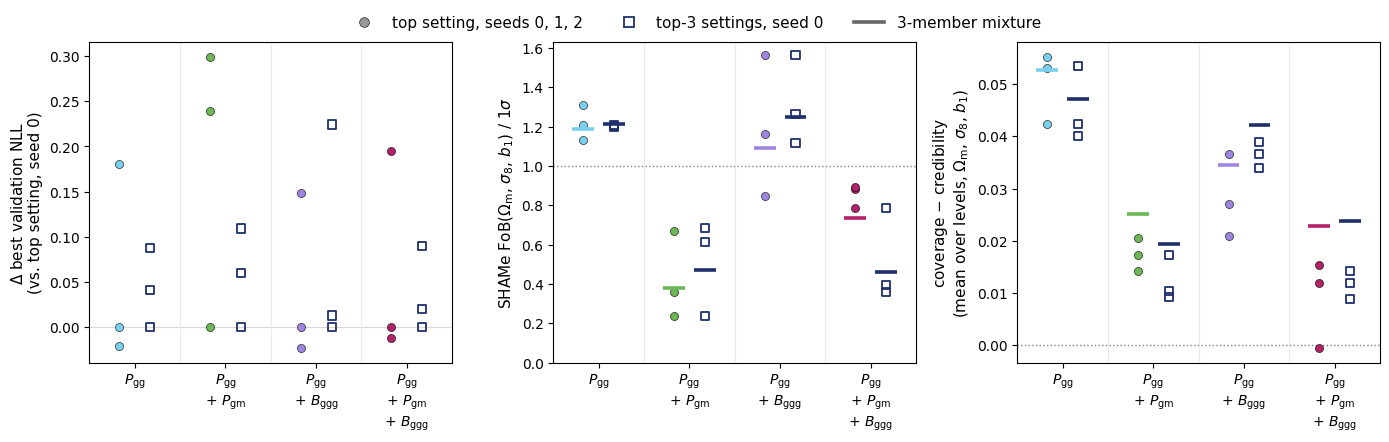

In [17]:
try:  # errors until every combo (P+Pgm) has its seeds/settings: skip without stopping a full run
    # FIRST VERSION: P_gm combos at the OLD fiducial (kpgm0.24, kpgm0.24-sweep networks), where all 5 networks
    # are tested; P and P+B are the same networks either way. Drop old_pgm_fiducial once the kpgm0.37
    # seeds/settings have their tests.
    fig_c, df_c = pf.plot_figC_seed_vs_hparam_scatter(old_pgm_fiducial=True)
except FileNotFoundError as e:
    fig_c, df_c = None, None
    print("Fig C: not made yet:", str(e)[:300])
eku.report_partial_ensembles("Fig C", note="FIRST VERSION: P+Pgm and P+Pgm+B at the OLD fiducial kpgm0.24 (kpgm0.24-sweep networks)")
df_c.round(3) if df_c is not None else None